In [ ]:
!pip install Paddleocr

In [ ]:
!pip install paddlepaddle-gpu

ERROR: Could not find a version that satisfies the requirement paddlepaddle-gpu (from versions: none)
ERROR: No matching distribution found for paddlepaddle-gpu


In [ ]:
import cv2
from paddleocr import PaddleOCR
import matplotlib.pyplot as plt

# Install PaddleOCR and PaddlePaddle if you haven't already
# !pip install paddlepaddle-gpu # or !pip install paddlepaddle if you don't have a GPU
# !pip install paddleocr

# Initialize PaddleOCR with the desired language (e.g., 'en' for English)
# You can specify other languages like 'ch' for Chinese, 'fr' for French, etc.
ocr = PaddleOCR(use_angle_cls=True, lang='en')

# Path to your image file
image_path = '/content/platenumber.jpeg' # <<< IMPORTANT: Replace with your image path

# Load the image
# It's good practice to check if the file exists and is a valid image
try:
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Image not found at {image_path} or it's not a valid image.")

    # Perform OCR
    result = ocr.predict(img)

    # Print extracted text
    print("Extracted Text:")
    for line in result:
        if line is not None:
            for word_info in line:
                # word_info is typically [bbox, (text, confidence)]
                if isinstance(word_info, list) and len(word_info) == 2:
                    text, confidence = word_info[1]
                    print(f"Text: {text}, Confidence: {confidence:.2f}")
                elif isinstance(word_info, tuple) and len(word_info) == 2: # Older PaddleOCR versions might return just (text, confidence)
                    text, confidence = word_info
                    print(f"Text: {text}, Confidence: {confidence:.2f}")
                else: # Fallback for unexpected format
                    print(f"Found: {word_info}")

    # Optional: Display the image with detected text bounding boxes
    # If you want to see the image with boxes, uncomment the following lines
    # from PIL import Image
    # boxes = [line[0] for line in result]
    # texts = [line[1][0] for line in result]
    # scores = [line[1][1] for line in result]
    # im_show = draw_ocr(img, boxes, texts, scores, font_path='./PaddleOCR/doc/fonts/simfang.ttf') # You might need to specify a font path
    # im_show = Image.fromarray(im_show)
    # plt.figure(figsize=(10, 10))
    # plt.imshow(im_show)
    # plt.axis('off')
    # plt.show()

except FileNotFoundError as e:
    print(f"Error: {e}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")


In [ ]:
# Install EasyOCR
!pip install easyocr

In [ ]:
import easyocr
import cv2
import matplotlib.pyplot as plt

# Initialize EasyOCR reader (can take some time on first run to download models)
# Specify the languages you want to recognize, e.g., ['en'] for English
reader = easyocr.Reader(['en'])

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

In [ ]:
# Path to your image file
image_path = '/content/platenumber.jpeg' # <<< IMPORTANT: Ensure this path is correct

# Load the image
try:
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Image not found at {image_path} or it's not a valid image.")

    # Perform OCR
    # The result contains a list of tuples, each containing (bbox, text, confidence)
    results = reader.readtext(img)

    # Print extracted text and confidence scores
    print("Extracted Text:")
    for (bbox, text, prob) in results:
        print(f"Text: {text}, Confidence: {prob:.2f}")

    # Optional: Display the image with detected text bounding boxes
    # (Uncomment the following lines to visualize)
    # for (bbox, text, prob) in results:
    #     # Unpack the bounding box coordinates
    #     (top_left, top_right, bottom_right, bottom_left) = bbox
    #     top_left = tuple(map(int, top_left))
    #     bottom_right = tuple(map(int, bottom_right))
    #
    #     # Draw the bounding box on the image
    #     cv2.rectangle(img, top_left, bottom_right, (0, 255, 0), 2) # Green rectangle, 2px thick
    #
    #     # Put the text near the bounding box
    #     cv2.putText(img, text, (top_left[0], top_left[1] - 10),
    #                 cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2) # Green text
    #
    # # Convert BGR to RGB for displaying with matplotlib
    # img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    #
    # plt.figure(figsize=(10, 10))
    # plt.imshow(img_rgb)
    # plt.axis('off')
    # plt.title('Image with Detected Text')
    # plt.show()

except FileNotFoundError as e:
    print(f"Error: {e}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Extracted Text:
Text: Lacu, Confidence: 0.18
Text: (JJJ A61yL, Confidence: 0.18


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def preprocess_image(image_path):
    # 1. Load the image in grayscale
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Image not found at {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 2. Resize the image (upscale by 2x using cubic interpolation for smoother edges)
    resized = cv2.resize(gray, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)

    # 3. Apply Bilateral Filter to remove noise while keeping edges sharp
    filtered = cv2.bilateralFilter(resized, 11, 17, 17)

    # 4. Apply Adaptive Thresholding (Binarization)
    binary = cv2.adaptiveThreshold(
        filtered, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
    )

    return img, gray, resized, binary

# Run preprocessing and plot the pipeline
try:
    original, gray, resized, binary = preprocess_image('/content/platenumber.jpeg')

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(gray, cmap='gray')
    axes[1].set_title("Grayscale")
    axes[1].axis('off')

    axes[2].imshow(binary, cmap='gray')
    axes[2].set_title("Preprocessed (Binarized)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Error processing image: {e}")

Error processing image: Image not found at /content/platenumber.jpeg


In [2]:
# Perform OCR on the preprocessed (binary) image
try:
    # EasyOCR can directly read a numpy array (preprocessed image)
    preprocessed_results = reader.readtext(binary)

    print("--- OCR Results on Preprocessed Image ---")
    for (bbox, text, prob) in preprocessed_results:
        print(f"Text: {text} | Confidence: {prob:.2f}")

except Exception as e:
    print(f"Error performing OCR: {e}")

Error performing OCR: name 'reader' is not defined


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 89.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 34.0 MB/s eta 0:00:00


Initializing EasyOCR...
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteRunning OCR on preprocessed image...

--- OCR Predictions after Preprocessing ---
Detected Text: Lnoox (Confidence: 0.3650)
Detected Text: JJJA6]YL (Confidence: 0.5160)


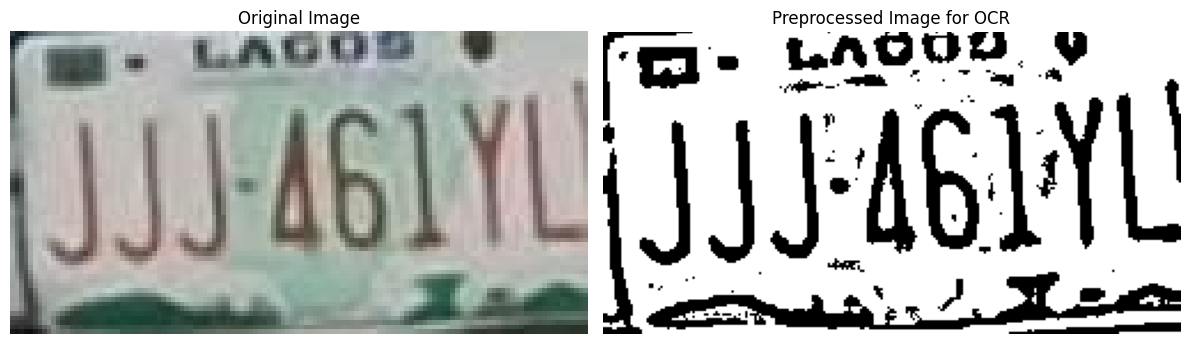

In [4]:
!pip install easyocr

import cv2
import easyocr
import numpy as np
import matplotlib.pyplot as plt

# 1. Initialize EasyOCR Reader
print("Initializing EasyOCR...")
reader = easyocr.Reader(['en'], gpu=False)  # Set gpu=True if you have an active GPU runtime

# 2. Image Preprocessing Pipeline
def preprocess_for_ocr(image_path):
    # Load image
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Cannot load image at {image_path}")

    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize (upscale 2x for clearer character boundaries)
    resized = cv2.resize(gray, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)

    # Denoise using bilateral filter (removes background noise while keeping edge details sharp)
    filtered = cv2.bilateralFilter(resized, 11, 17, 17)

    # Adaptive Thresholding (converts to sharp black and white contrast)
    binary = cv2.adaptiveThreshold(
        filtered, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
    )

    return img, binary

# 3. Execute Preprocessing & OCR
try:
    image_path = '/content/platenumber.jpeg'
    original_img, processed_img = preprocess_for_ocr(image_path)

    # Perform prediction on preprocessed image
    print("Running OCR on preprocessed image...")
    results = reader.readtext(processed_img)

    # Print Results
    print("\n--- OCR Predictions after Preprocessing ---")
    if not results:
        print("No text detected. Trying on original grayscale image...")
        gray_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2GRAY)
        results = reader.readtext(gray_img)

    for (bbox, text, prob) in results:
        print(f"Detected Text: {text} (Confidence: {prob:.4f})")

    # Plot comparison side by side
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(processed_img, cmap='gray')
    axes[1].set_title("Preprocessed Image for OCR")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred during experiment execution: {e}")


--- Results for: Original Grayscale ---
Text: Lacu | Confidence: 0.1896
Text: 6jja61yL | Confidence: 0.3043

--- Results for: Otsu Thresholding ---
Text: (JJJA61YL | Confidence: 0.3057

--- Results for: Gaussian Blur + Otsu ---
Text: {JJJI6LYL | Confidence: 0.1560

--- Results for: Morphological Closed ---
No text detected


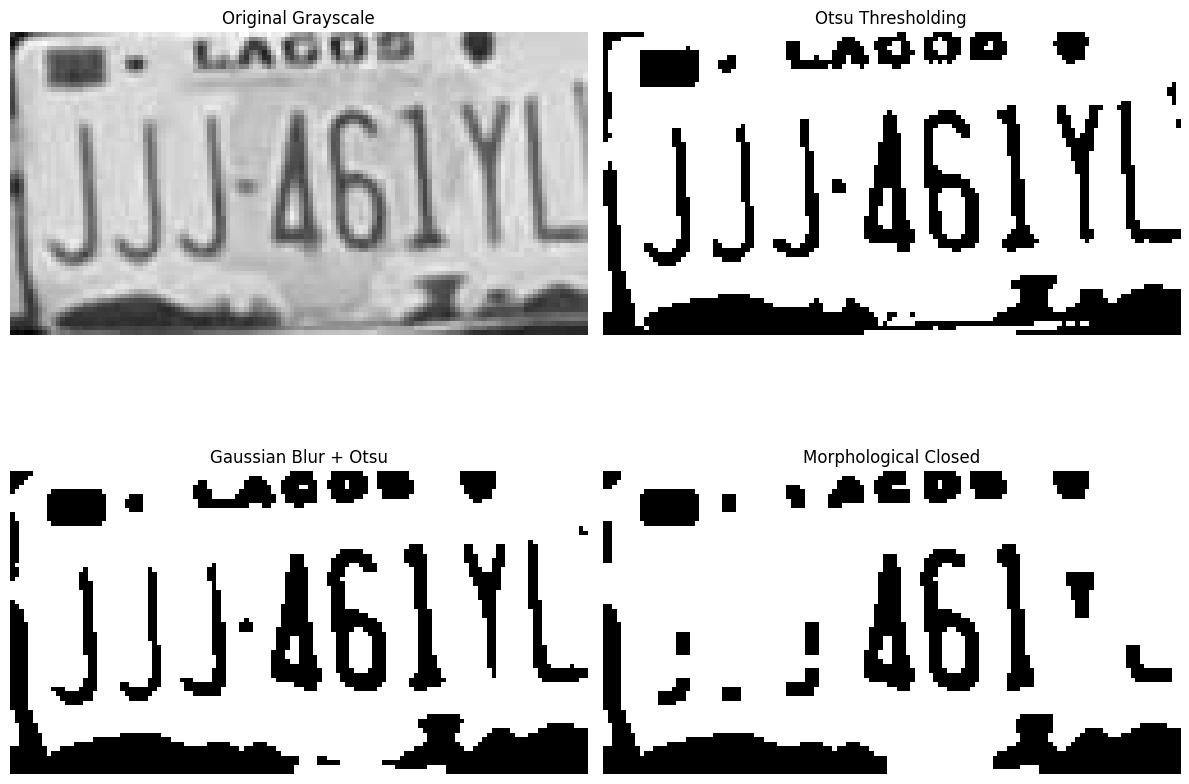

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def experiment_preprocessing(image_path):
    # Load image
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Cannot find {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Standard Otsu's Thresholding
    _, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Gaussian Blur followed by Otsu's Thresholding
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, otsu_blur = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 3. Morphological opening to clean up noise (dilation followed by erosion)
    kernel = np.ones((3, 3), np.uint8)
    morph = cv2.morphologyEx(otsu_blur, cv2.MORPH_CLOSE, kernel)

    return {
        'Original Grayscale': gray,
        'Otsu Thresholding': otsu,
        'Gaussian Blur + Otsu': otsu_blur,
        'Morphological Closed': morph
    }

# Run experiments
images_dict = experiment_preprocessing('/content/platenumber.jpeg')

# Test OCR predictions for each variant
for name, img_variant in images_dict.items():
    results = reader.readtext(img_variant)
    print(f"\n--- Results for: {name} ---")
    if not results:
        print("No text detected")
    for (bbox, text, prob) in results:
        print(f"Text: {text} | Confidence: {prob:.4f}")

# Plot the variants
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()
for i, (name, img_variant) in enumerate(images_dict.items()):
    axes[i].imshow(img_variant, cmap='gray')
    axes[i].set_title(name)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

--- OCR Results for Cropped + CLAHE ---
Text: JJJ A61YL | Confidence: 0.5350

--- OCR Results for Cropped + Otsu ---
Text: JJJIGiYL | Confidence: 0.2767


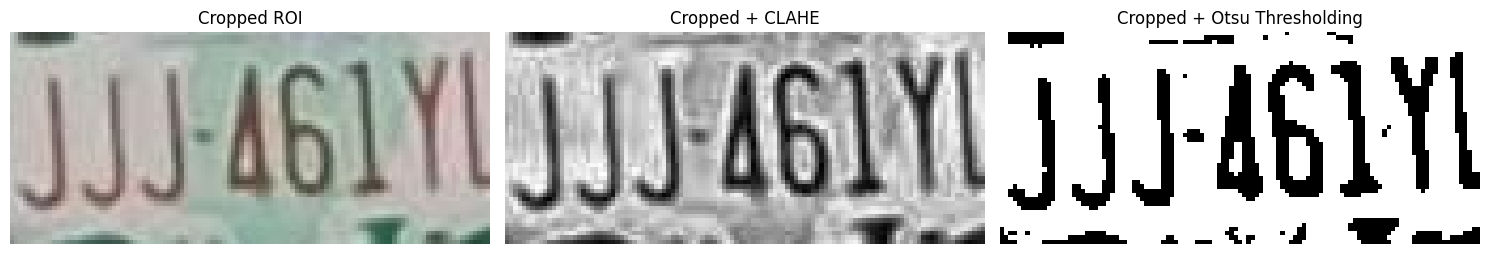

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load original image
img = cv2.imread('/content/platenumber.jpeg')
h, w, _ = img.shape

# Crop the region of interest (ROI) containing the plate number
# For this image, let's crop slightly away from the outer edges to get clean text
y_start, y_end = int(h * 0.15), int(h * 0.90)
x_start, x_end = int(w * 0.05), int(w * 0.95)
cropped = img[y_start:y_end, x_start:x_end]

# Preprocess Cropped ROI
cropped_gray = cv2.cvtColor(cropped, cv2.COLOR_BGR2GRAY)

# Apply CLAHE to enhance local contrast
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
cropped_enhanced = clahe.apply(cropped_gray)

# Otsu's Thresholding on Enhanced Crop
_, cropped_otsu = cv2.threshold(cropped_enhanced, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Run predictions
print("--- OCR Results for Cropped + CLAHE ---")
results_clahe = reader.readtext(cropped_enhanced)
for bbox, text, prob in results_clahe:
    print(f"Text: {text} | Confidence: {prob:.4f}")

print("\n--- OCR Results for Cropped + Otsu ---")
results_otsu = reader.readtext(cropped_otsu)
for bbox, text, prob in results_otsu:
    print(f"Text: {text} | Confidence: {prob:.4f}")

# Visualize side-by-side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
axes[0].set_title("Cropped ROI")
axes[0].axis('off')

axes[1].imshow(cropped_enhanced, cmap='gray')
axes[1].set_title("Cropped + CLAHE")
axes[1].axis('off')

axes[2].imshow(cropped_otsu, cmap='gray')
axes[2].set_title("Cropped + Otsu Thresholding")
axes[2].axis('off')

plt.tight_layout()
plt.show()